# дисбаланс классов, roc/auc и ансамбли

данные о клиентах телеком-компании

цель найти клиентов, которые могут уйти

## шаг 1 - импорт библиотек

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score

random_state = 42

## шаг 2 - загрузка данных и целевая переменная

In [2]:
df = pd.read_csv("ai_customer_churn_lab5.csv")

x = df.drop(columns="Churn")
y = (df["Churn"] == "Да").astype(int)

print("строк в таблице:", len(df))
print("признаков у клиента:", x.shape[1])
print("первый клиент:")
print(df.head(3).to_string(index=False))

строк в таблице: 800
признаков у клиента: 8
первый клиент:
 Age  TenureMonths  MonthlySpend  UsageHours  SupportCalls     Plan InternetType AutoPay Churn
  43            45        3744.0        39.7             2  Базовый       Кабель      Да   Нет
  27            44        3766.0        45.4             2 Стандарт       Оптика      Да   Нет
  48            14        1056.0        43.8             0 Стандарт       Оптика     Нет   Нет


## шаг 3 - доли классов и дисбаланс

In [3]:
count_zero = int((y == 0).sum())
count_one = int((y == 1).sum())
share_one = count_one / len(y)

print("-" * 55)
print(f"{'класс':<16}{'клиентов':>12}{'доля':>12}")
print("-" * 55)
print(f"{'остался (0)':<16}{count_zero:>12}{count_zero / len(y):>12.3f}")
print(f"{'ушёл (1)':<16}{count_one:>12}{share_one:>12.3f}")
print("-" * 55)

if share_one < 0.5:
    print("вывод: класс 1 редкий, есть дисбаланс")
else:
    print("вывод: классы сбалансированы")

-------------------------------------------------------
класс               клиентов        доля
-------------------------------------------------------
остался (0)              713       0.891
ушёл (1)                  87       0.109
-------------------------------------------------------
вывод: класс 1 редкий, есть дисбаланс


## шаг 4 - train/test со стратификацией

In [4]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.20,
    random_state=random_state,
    stratify=y
)

print("train:", x_train.shape)
print("test :", x_test.shape)
print("доля класса 1 в train:", round(y_train.mean(), 3))
print("доля класса 1 в test :", round(y_test.mean(), 3))

train: (640, 8)
test : (160, 8)
доля класса 1 в train: 0.109
доля класса 1 в test : 0.106


## шаг 5 - подготовка признаков

In [5]:
numeric_features = ["Age", "TenureMonths", "MonthlySpend", "UsageHours", "SupportCalls"]
categorical_features = ["Plan", "InternetType", "AutoPay"]

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

print("числовые признаки:", len(numeric_features))
print("категориальные признаки:", len(categorical_features))

числовые признаки: 5
категориальные признаки: 3


## шаг 6 - четыре модели и pipeline

In [6]:
models = {}
models["logistic"] = LogisticRegression(max_iter=1000)
models["logistic_balanced"] = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)
models["forest"] = RandomForestClassifier(
    n_estimators=200,
    max_depth=6,
    random_state=random_state
)
models["forest_balanced"] = RandomForestClassifier(
    n_estimators=200,
    max_depth=6,
    class_weight="balanced",
    random_state=random_state
)

pipelines = {}
for name in models:
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", models[name])
    ])
    pipelines[name] = pipeline

print("моделей:", len(pipelines))

моделей: 4


## шаг 7 - обучение и таблица метрик

In [7]:
rows = []
predictions = {}
probabilities = {}

for name in pipelines:
    model = pipelines[name]
    model.fit(x_train, y_train)
    pred = model.predict(x_test)
    prob = model.predict_proba(x_test)[:, 1]
    predictions[name] = pred
    probabilities[name] = prob
    rows.append({
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred, zero_division=0),
        "f1": f1_score(y_test, pred, zero_division=0),
        "auc": roc_auc_score(y_test, prob)
    })

results = pd.DataFrame(rows)
results = results.sort_values("f1", ascending=False)
print(results.round(3).to_string(index=False))

            model  accuracy  precision  recall    f1   auc
logistic_balanced     0.688      0.176   0.529 0.265 0.708
  forest_balanced     0.806      0.182   0.235 0.205 0.650
         logistic     0.888      0.333   0.059 0.100 0.718
           forest     0.888      0.000   0.000 0.000 0.668


## шаг 8 - матрицы ошибок random forest

In [8]:
def error_counts(pred):
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return tn, fp, fn, tp

tn_1, fp_1, fn_1, tp_1 = error_counts(predictions["forest"])
tn_2, fp_2, fn_2, tp_2 = error_counts(predictions["forest_balanced"])

print("-" * 58)
print(f"{'модель':<20}{'tn':>6}{'fp':>6}{'fn':>6}{'tp':>6}")
print("-" * 58)
print(f"{'forest':<20}{tn_1:>6}{fp_1:>6}{fn_1:>6}{tp_1:>6}")
print(f"{'forest balanced':<20}{tn_2:>6}{fp_2:>6}{fn_2:>6}{tp_2:>6}")
print("-" * 58)

----------------------------------------------------------
модель                  tn    fp    fn    tp
----------------------------------------------------------
forest                 142     1    17     0
forest balanced        125    18    13     4
----------------------------------------------------------


## шаг 9 - roc-кривые и auc

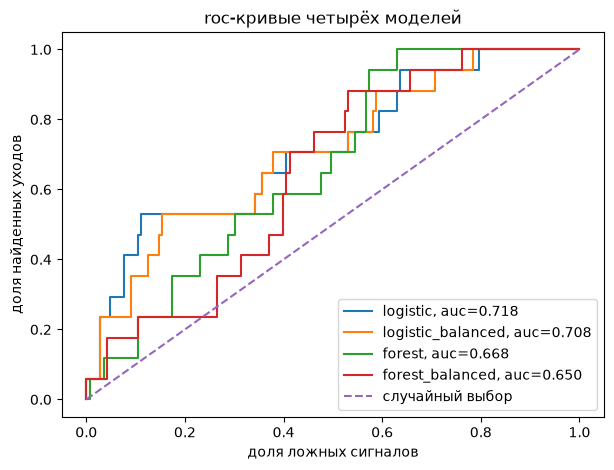

In [9]:
plt.figure(figsize=(7, 5))

for name in probabilities:
    prob = probabilities[name]
    fpr, tpr, thresholds = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    plt.plot(fpr, tpr, label=f"{name}, auc={auc:.3f}")

plt.plot([0, 1], [0, 1], linestyle="--", label="случайный выбор")
plt.xlabel("доля ложных сигналов")
plt.ylabel("доля найденных уходов")
plt.title("roc-кривые четырёх моделей")
plt.legend()
plt.show()

## шаг 10 - выбор порога

In [10]:
best_name = results.iloc[0]["model"]
best_prob = probabilities[best_name]
threshold_rows = []

for threshold in [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]:
    pred_t = (best_prob >= threshold).astype(int)
    threshold_rows.append({
        "порог": threshold,
        "precision": precision_score(y_test, pred_t, zero_division=0),
        "recall": recall_score(y_test, pred_t, zero_division=0),
        "f1": f1_score(y_test, pred_t, zero_division=0),
        "сигналов": int(pred_t.sum())
    })

threshold_results = pd.DataFrame(threshold_rows)
print("лучшая модель по f1:", best_name)
print(threshold_results.round(3).to_string(index=False))

лучшая модель по f1: logistic_balanced
 порог  precision  recall    f1  сигналов
   0.2      0.130   1.000 0.230       131
   0.3      0.138   0.882 0.238       109
   0.4      0.154   0.706 0.253        78
   0.5      0.176   0.529 0.265        51
   0.6      0.265   0.529 0.353        34
   0.7      0.250   0.235 0.242        16


## шаг 11 - кросс-валидация

In [11]:
scoring = {"f1": "f1", "auc": "roc_auc"}
cv_rows = []

for name in pipelines:
    scores = cross_validate(
        pipelines[name], x_train, y_train,
        cv=5,
        scoring=scoring
    )
    cv_rows.append({
        "model": name,
        "cv_f1_mean": scores["test_f1"].mean(),
        "cv_f1_std": scores["test_f1"].std(),
        "cv_auc_mean": scores["test_auc"].mean()
    })

cv_results = pd.DataFrame(cv_rows)
cv_results = cv_results.sort_values("cv_f1_mean", ascending=False)
print(cv_results.round(3).to_string(index=False))

            model  cv_f1_mean  cv_f1_std  cv_auc_mean
logistic_balanced       0.340      0.057        0.732
  forest_balanced       0.332      0.103        0.675
         logistic       0.209      0.066        0.748
           forest       0.080      0.065        0.679


## шаг 12 - важность признаков

In [12]:
forest_pipe = pipelines["forest"]
names = forest_pipe.named_steps["preprocessor"].get_feature_names_out()
importance = forest_pipe.named_steps["classifier"].feature_importances_
importance_rows = []

for i in range(len(names)):
    importance_rows.append({
        "признак": names[i],
        "важность": importance[i]
    })

importance_results = pd.DataFrame(importance_rows)
importance_results = importance_results.sort_values("важность", ascending=False)
print(importance_results.head(5).round(3).to_string(index=False))

          признак  важность
num__TenureMonths     0.212
  num__UsageHours     0.193
num__MonthlySpend     0.153
num__SupportCalls     0.131
         num__Age     0.105


## шаг 13 - проверка ключевых чисел

In [13]:
checks = []
checks.append(("всего клиентов", 800, len(df), len(df) == 800))
checks.append(("доля ушедших меньше 0.2", "да", round(share_one, 3), share_one < 0.2))
checks.append(("размер train", 640, len(x_train), len(x_train) == 640))
checks.append(("размер test", 160, len(x_test), len(x_test) == 160))
checks.append(("обучено моделей", 4, len(results), len(results) == 4))
checks.append(("лучший auc выше 0.5", "да", round(results["auc"].max(), 3), results["auc"].max() > 0.5))
checks.append(("сумма важностей равна 1", 1.0, round(importance.sum(), 3), np.abs(importance.sum() - 1.0) < 0.01))

low_recall = threshold_results[threshold_results["порог"] == 0.20]["recall"].iloc[0]
mid_recall = threshold_results[threshold_results["порог"] == 0.50]["recall"].iloc[0]
checks.append(("recall при 0.20 не ниже 0.50", "да", round(low_recall, 3), low_recall >= mid_recall))

print("-" * 62)
print(f"{'проверка':<34}{'ожидание':>10}{'факт':>10}{'итог':>8}")
print("-" * 62)

correct = 0
for name, expected, actual, ok in checks:
    mark = "да" if ok else "нет"
    if ok:
        correct = correct + 1
    print(f"{name:<34}{str(expected):>10}{str(actual):>10}{mark:>8}")

print("-" * 62)
print(f"правильно: {correct} из {len(checks)}")

--------------------------------------------------------------
проверка                            ожидание      факт    итог
--------------------------------------------------------------
всего клиентов                           800       800      да
доля ушедших меньше 0.2                   да     0.109      да
размер train                             640       640      да
размер test                              160       160      да
обучено моделей                            4         4      да
лучший auc выше 0.5                       да     0.718      да
сумма важностей равна 1                  1.0       1.0      да
recall при 0.20 не ниже 0.50              да       1.0      да
--------------------------------------------------------------
правильно: 8 из 8


## итог

лучшая модель по f1 на test: logistic_balanced

порог 0.20 даёт recall 1.000 при precision 0.130

балансировка повышает recall, но увеличивает ложные сигналы